# SoC Type Distribution Analysis
Analysis of stream-of-consciousness type frequencies across Joyce, Woolf, Richardson, Faulkner, and Sinclair, using the silver-label data produced by the Penelope pipeline.

**Research questions:**
1. What percentage of *Ulysses* is direct + indirect interior monologue, and is it lower than in Woolf and/or Richardson?
2. Is Woolf an outlier in terms of SoC type frequency across her works, and how does she compare to Joyce and Richardson?

**Data sources:**
- `silver_data/` — three frontier-model passes (gpt-5.4, mercury-2, qwen3-max); used for all corpus-wide analysis
- `training_data/` — four-model passes including gemini-3-pro-preview and gpt-5; contains `Mrs_Dalloway.txt` under a different filename than `silver_data/`

**Note:** `Mrs Dalloway` and `To the Lighthouse` are nearly absent from `silver_data/` (1–2 records each) due to a filename mismatch (`pg05765_mrs_dalloway.txt` / `pg00690_to_the_lighthouse.txt` were not included in that pipeline run). The Dalloway analysis below uses `training_data/` instead.

In [2]:
%pip install matplotlib numpy pandas -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import pathlib
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# ── Paths ─────────────────────────────────────────────────────────────────
ROOT = pathlib.Path(".")   # run from repo root, or adjust
SILVER_DIR = ROOT / "silver_data"
TRAINING_DIR = ROOT / "training_data"

# ── Work registry ─────────────────────────────────────────────────────────
# Maps source_file → (author, short_title).
# silver_data uses PG-prefixed filenames; training_data uses plain names.
SILVER_WORKS = {
    "pg04300_ulysses.txt":           ("Joyce",       "Ulysses"),
    "pg04217_a_portrait_of_the_artist_as_a_young_man.txt": ("Joyce", "Portrait"),
    "pg02814_dubliners.txt":         ("Joyce",       "Dubliners"),
    "pg43524_the_waves.txt":         ("Woolf",       "The Waves"),
    "jacobs_room.txt":               ("Woolf",       "Jacob's Room"),
    "between_the_acts.txt":          ("Woolf",       "Between the Acts"),
    "the_years.txt":                 ("Woolf",       "The Years"),
    "the_voyage_out.txt":            ("Woolf",       "The Voyage Out"),
    "orlando_cleaned.txt":           ("Woolf",       "Orlando"),
    "pg04517_pointed_roofs.txt":     ("Richardson",  "Pointed Roofs"),
    "pg04518_backwater.txt":         ("Richardson",  "Backwater"),
    "pg04519_honeycomb.txt":         ("Richardson",  "Honeycomb"),
    "pg34219_mary_olivier_a_life.txt": ("Sinclair",  "Mary Olivier"),
    "sound_and_fury.txt":            ("Faulkner",    "Sound & Fury"),
    "as_I_lay_dying.txt":            ("Faulkner",    "As I Lay Dying"),
}

TRAINING_WORKS = {
    "Mrs_Dalloway.txt": ("Woolf", "Mrs Dalloway"),
}

# Deprecated types → other_soc
DEPRECATED = {"soliloquy", "space_montage"}
TYPES_ORDERED = [
    "direct_interior_monologue",
    "indirect_interior_monologue",
    "omniscient_description",
    "simulation_state_of_mind",
    "imagery",
    "reverie_fantasy",
    "free_association",
    "hybrid",
    "orthographic_marker",
    "other_soc",
]
TYPE_SHORT = {
    "direct_interior_monologue":    "direct",
    "indirect_interior_monologue":  "indirect",
    "omniscient_description":       "omniscient",
    "simulation_state_of_mind":     "simulation",
    "imagery":                      "imagery",
    "reverie_fantasy":              "reverie",
    "free_association":             "free_assoc",
    "hybrid":                       "hybrid",
    "orthographic_marker":          "orthographic",
    "other_soc":                    "other",
}

def load_records(data_dir, work_map):
    """Load all JSON files from data_dir, tag with model, filter to work_map."""
    records = []
    for f in sorted(data_dir.glob("*.json")):
        data = json.loads(f.read_text())
        for r in data:
            if r.get("source_file") in work_map:
                r["_model"] = f.stem
                records.append(r)
    return records

def dedup_records(records, work_map):
    """Deduplicate by (source_file, first-80-chars-of-passage) — removes
    near-identical rows from the same passage across models."""
    seen = set()
    out = []
    for r in records:
        key = (r.get("source_file", ""), r.get("passage", "")[:80])
        if key not in seen:
            seen.add(key)
            out.append(r)
    return out

def normalise_type(t):
    if not t or t == "none":
        return "other_soc"
    t = t.strip()
    if t in DEPRECATED:
        return "other_soc"
    return t

def build_work_df(records, work_map):
    """Return a DataFrame with one row per work, columns = type fractions."""
    work_counts = defaultdict(lambda: defaultdict(int))
    for r in records:
        sf = r.get("source_file", "")
        author, title = work_map[sf]
        t = normalise_type(r.get("soc_type", ""))
        label = f"{author}: {title}"
        work_counts[label][t] += 1

    rows = []
    for label, counts in work_counts.items():
        total = sum(counts.values())
        row = {"work": label, "n": total}
        for t in TYPES_ORDERED:
            row[t] = counts.get(t, 0) / total if total else 0.0
        row["author"] = label.split(":")[0]
        rows.append(row)
    return pd.DataFrame(rows).set_index("work").sort_values(["author", "n"], ascending=[True, False])

# ── Load ──────────────────────────────────────────────────────────────────
silver_raw   = load_records(SILVER_DIR, SILVER_WORKS)
silver_dedup = dedup_records(silver_raw, SILVER_WORKS)

training_raw   = load_records(TRAINING_DIR, TRAINING_WORKS)
training_dedup = dedup_records(training_raw, TRAINING_WORKS)

print(f"silver_data  : {len(silver_raw):5d} raw → {len(silver_dedup):5d} deduped records")
print(f"training_data: {len(training_raw):5d} raw → {len(training_dedup):5d} deduped records (Mrs Dalloway)")
print(f"\nWorks in silver_data:")
for label in sorted(set(f"{SILVER_WORKS[r['source_file']][0]}: {SILVER_WORKS[r['source_file']][1]}" for r in silver_dedup)):
    print(f"  {label}")

silver_data  : 12191 raw → 10053 deduped records
training_data:  1612 raw →  1125 deduped records (Mrs Dalloway)

Works in silver_data:
  Faulkner: As I Lay Dying
  Faulkner: Sound & Fury
  Joyce: Dubliners
  Joyce: Portrait
  Joyce: Ulysses
  Richardson: Backwater
  Richardson: Honeycomb
  Richardson: Pointed Roofs
  Sinclair: Mary Olivier
  Woolf: Between the Acts
  Woolf: Jacob's Room
  Woolf: Orlando
  Woolf: The Voyage Out
  Woolf: The Waves
  Woolf: The Years


## Q1: Direct + Indirect interior monologue in Ulysses vs. Woolf and Richardson

In [4]:
df = build_work_df(silver_dedup, SILVER_WORKS)

# Add Mrs Dalloway from training_data
dall_df = build_work_df(training_dedup, TRAINING_WORKS)
df = pd.concat([df, dall_df])

# Build Q1 summary table
q1 = df[["n", "direct_interior_monologue", "indirect_interior_monologue", "author"]].copy()
q1["combined"] = q1["direct_interior_monologue"] + q1["indirect_interior_monologue"]
q1 = q1.sort_values(["author", "combined"], ascending=[True, False])

# Format for display
q1_display = q1[["n", "direct_interior_monologue", "indirect_interior_monologue", "combined"]].copy()
q1_display.columns = ["n", "direct %", "indirect %", "combined %"]
for col in ["direct %", "indirect %", "combined %"]:
    q1_display[col] = (q1_display[col] * 100).round(1)

print(q1_display.to_string())
print()
print("Key: 'combined' = direct + indirect interior monologue as % of all SoC instances")

                              n  direct %  indirect %  combined %
work                                                             
Faulkner: As I Lay Dying    625      43.8        17.3        61.1
Faulkner: Sound & Fury      737      41.9        11.4        53.3
Joyce: Ulysses             2174      38.9        21.4        60.3
Joyce: Dubliners            345       7.8        43.2        51.0
Joyce: Portrait             695      11.7        39.1        50.8
Richardson: Honeycomb       490       8.4        43.9        52.2
Richardson: Backwater       106      10.4        39.6        50.0
Richardson: Pointed Roofs   329       8.8        40.1        48.9
Sinclair: Mary Olivier      261      19.5        24.9        44.4
Woolf: Mrs Dalloway        1125       3.8        72.5        76.4
Woolf: The Years           1485      17.7        46.4        64.1
Woolf: Between the Acts     388      17.8        37.4        55.2
Woolf: The Waves            702      32.3        20.8        53.1
Woolf: Orl

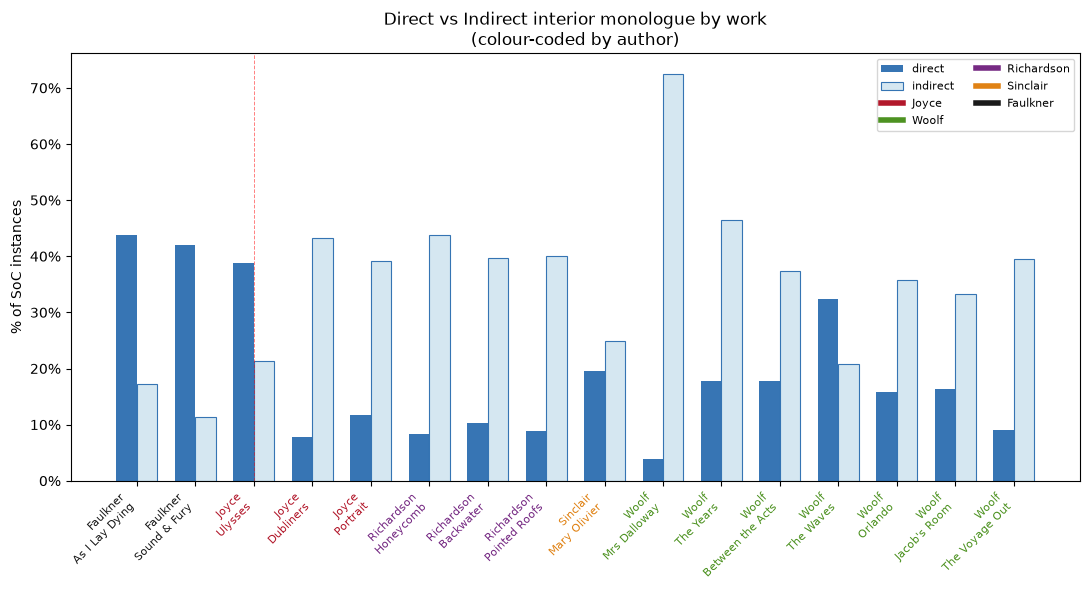

Saved: logs/q1_direct_indirect.png


In [5]:
fig, ax = plt.subplots(figsize=(11, 6))

works = q1.index.tolist()
x = np.arange(len(works))
w = 0.35

direct_vals   = (q1["direct_interior_monologue"] * 100).values
indirect_vals = (q1["indirect_interior_monologue"] * 100).values

bars_d = ax.bar(x - w/2, direct_vals,   w, label="direct",   color="#2166ac", alpha=0.9)
bars_i = ax.bar(x + w/2, indirect_vals, w, label="indirect", color="#d1e5f0", alpha=0.9, edgecolor="#2166ac", linewidth=0.8)

# Mark Ulysses
ulysses_idx = works.index("Joyce: Ulysses")
ax.axvline(ulysses_idx, color="red", linewidth=0.7, linestyle="--", alpha=0.5)

# Colour x-tick labels by author
AUTHOR_COLORS = {"Joyce": "#b2182b", "Woolf": "#4d9221", "Richardson": "#762a83", "Sinclair": "#e08214", "Faulkner": "#1a1a1a"}
ax.set_xticks(x)
ax.set_xticklabels([w.replace(": ", "\n") for w in works], rotation=45, ha="right", fontsize=8)
for tick, work in zip(ax.get_xticklabels(), works):
    author = work.split(":")[0]
    tick.set_color(AUTHOR_COLORS.get(author, "black"))

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("% of SoC instances")
ax.set_title("Direct vs Indirect interior monologue by work\n(colour-coded by author)")
ax.legend()

# Author legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], color=c, lw=4, label=a) for a, c in AUTHOR_COLORS.items()]
ax.legend(handles=[bars_d, bars_i] + legend_elements, loc="upper right", fontsize=8, ncol=2)

plt.tight_layout()
plt.savefig("logs/q1_direct_indirect.png", dpi=150)
plt.show()
print("Saved: logs/q1_direct_indirect.png")

## Q2: Is Woolf an outlier? Author-level and within-Woolf comparisons

In [6]:
# Author-level aggregate (weight each work equally by record count)
all_records = silver_dedup + training_dedup
all_works = {**SILVER_WORKS, **TRAINING_WORKS}

author_counts = defaultdict(lambda: defaultdict(int))
author_totals = defaultdict(int)
for r in all_records:
    sf = r.get("source_file", "")
    if sf not in all_works:
        continue
    author, _ = all_works[sf]
    t = normalise_type(r.get("soc_type", ""))
    author_counts[author][t] += 1
    author_totals[author] += 1

author_rows = []
for author in ["Joyce", "Woolf", "Richardson", "Sinclair", "Faulkner"]:
    if author not in author_totals:
        continue
    n = author_totals[author]
    row = {"author": author, "n": n}
    for t in TYPES_ORDERED:
        row[TYPE_SHORT[t]] = author_counts[author].get(t, 0) / n
    author_rows.append(row)

author_df = pd.DataFrame(author_rows).set_index("author")

# Display
display_cols = list(TYPE_SHORT.values())
pct_df = (author_df[display_cols] * 100).round(1)
pct_df["n"] = author_df["n"]
print(pct_df[["n"] + display_cols].to_string())

               n  direct  indirect  omniscient  simulation  imagery  reverie  free_assoc  hybrid  orthographic  other
author                                                                                                               
Joyce       3214    29.7      27.6         3.7         6.8      4.0      8.0         7.4    11.7           0.4    0.7
Woolf       5416    15.2      44.8        11.0         8.0      3.1      6.1         1.6     7.6           0.3    2.2
Richardson   925     8.8      42.1        15.8        17.3      4.2      3.4         0.1     6.9           0.6    0.9
Sinclair     261    19.5      24.9        16.5        22.6      1.9      5.7         0.4     4.2           0.8    3.4
Faulkner    1362    42.8      14.1         4.0         7.9      7.6      5.1         3.6    12.5           0.7    1.6


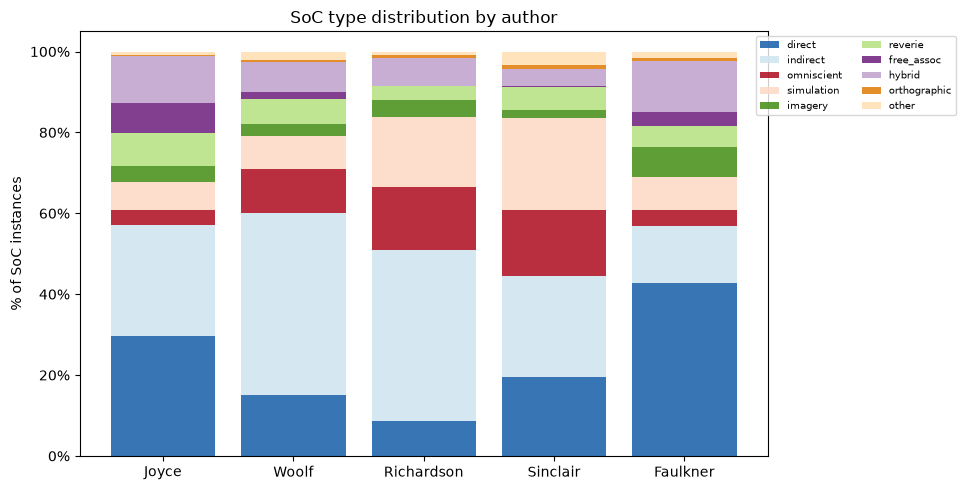

Saved: logs/q2_author_profiles.png


In [7]:
# Stacked bar chart — author-level type profiles
fig, ax = plt.subplots(figsize=(10, 5))

authors = list(author_df.index)
cols = list(TYPE_SHORT.values())
PALETTE = ["#2166ac","#d1e5f0","#b2182b","#fddbc7","#4d9221","#b8e186","#762a83","#c2a5cf","#e08214","#fee0b6"]

bottom = np.zeros(len(authors))
for i, col in enumerate(cols):
    vals = author_df[col].values
    ax.bar(authors, vals * 100, bottom=bottom * 100, label=col, color=PALETTE[i % len(PALETTE)], alpha=0.9)
    bottom += vals

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("% of SoC instances")
ax.set_title("SoC type distribution by author")
ax.legend(loc="upper right", fontsize=7, ncol=2, bbox_to_anchor=(1.28, 1))
plt.tight_layout()
plt.savefig("logs/q2_author_profiles.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: logs/q2_author_profiles.png")

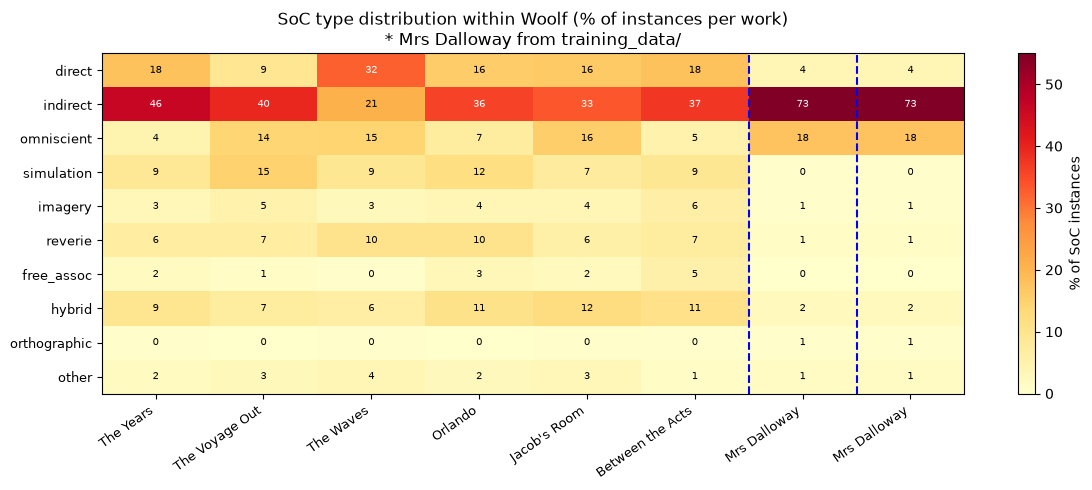

Saved: logs/q2_woolf_heatmap.png


In [8]:
# Within-Woolf variation — heatmap of type fractions across all Woolf works
woolf_works = df[df["author"] == "Woolf"]

# Add Mrs Dalloway
woolf_works = pd.concat([woolf_works, dall_df])

fig, ax = plt.subplots(figsize=(12, 5))

cols = TYPES_ORDERED
data = woolf_works[cols].values * 100
im = ax.imshow(data.T, aspect="auto", cmap="YlOrRd", vmin=0, vmax=55)

ax.set_xticks(range(len(woolf_works)))
ax.set_xticklabels([w.replace("Woolf: ", "") for w in woolf_works.index], rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(cols)))
ax.set_yticklabels([TYPE_SHORT[t] for t in cols], fontsize=9)

# Annotate cells
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        ax.text(i, j, f"{v:.0f}", ha="center", va="center", fontsize=7,
                color="white" if v > 30 else "black")

plt.colorbar(im, ax=ax, label="% of SoC instances")
ax.set_title("SoC type distribution within Woolf (% of instances per work)\n* Mrs Dalloway from training_data/")
# Mark Mrs Dalloway
dall_idx = list(woolf_works.index).index("Woolf: Mrs Dalloway")
ax.axvline(dall_idx - 0.5, color="blue", linewidth=1.5, linestyle="--")
ax.axvline(dall_idx + 0.5, color="blue", linewidth=1.5, linestyle="--")

plt.tight_layout()
plt.savefig("logs/q2_woolf_heatmap.png", dpi=150)
plt.show()
print("Saved: logs/q2_woolf_heatmap.png")

## Mrs Dalloway in training_data — type distribution and data source note

In [9]:
# Show which models contributed to the training_data Dalloway records
model_counts = defaultdict(int)
for r in training_raw:
    model_counts[r["_model"]] += 1

print("training_data — Mrs_Dalloway.txt records by model:")
for model, n in sorted(model_counts.items()):
    print(f"  {model:<30}  {n:4d}")
print(f"  {'TOTAL':<30}  {sum(model_counts.values()):4d}")
print()

# Type breakdown for Dalloway
dall_type_counts = defaultdict(int)
for r in training_dedup:
    t = normalise_type(r.get("soc_type", ""))
    dall_type_counts[t] += 1

total = sum(dall_type_counts.values())
print("Mrs Dalloway — SoC type breakdown (deduped, all models combined):")
for t in TYPES_ORDERED:
    n = dall_type_counts.get(t, 0)
    print(f"  {TYPE_SHORT[t]:<15}  {n:4d}  ({100*n/total:.1f}%)")
print(f"  {'TOTAL':<15}  {total:4d}")

training_data — Mrs_Dalloway.txt records by model:
  gemini-3-pro-preview             346
  gpt-5                            735
  mercury-2                        146
  qwen3-max                        385
  TOTAL                           1612

Mrs Dalloway — SoC type breakdown (deduped, all models combined):
  direct             43  (3.8%)
  indirect          816  (72.5%)
  omniscient        197  (17.5%)
  simulation          4  (0.4%)
  imagery             7  (0.6%)
  reverie            10  (0.9%)
  free_assoc          0  (0.0%)
  hybrid             26  (2.3%)
  orthographic        6  (0.5%)
  other              16  (1.4%)
  TOTAL            1125


## Cross-model agreement on type labels (silver_data)
How consistent are the three silver models on type assignments for each work? High agreement = clean training signal. Low agreement = candidate for the ambiguity dataset (see AMBIGUITY.md).

In [10]:
# For each work, group passages by fuzzy overlap (MIN_OVERLAP_RATIO = 0.35)
# and compute the fraction of groups where all models agree on soc_type.
# This is a rough single-pass proxy for cross-model agreement.

import re

MIN_OVERLAP_RATIO = 0.35

def normalise_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def token_overlap(a, b):
    if not a or not b:
        return 0.0
    intersection = len(a & b)
    return intersection / min(len(a), len(b))

def compute_agreement(records, work_map):
    """Return per-work fraction of passage groups where all models agree on type."""
    # Group by source_file
    by_work = defaultdict(list)
    for r in records:
        sf = r.get("source_file", "")
        if sf in work_map:
            r["_tokens"] = set(normalise_text(r.get("passage", "")).split())
            by_work[sf].append(r)

    results = {}
    for sf, recs in by_work.items():
        author, title = work_map[sf]
        label = f"{author}: {title}"

        # Group by passage overlap
        groups = []
        for r in recs:
            matched = False
            for g in groups:
                if token_overlap(r["_tokens"], g[0]["_tokens"]) >= MIN_OVERLAP_RATIO:
                    g.append(r)
                    matched = True
                    break
            if not matched:
                groups.append([r])

        # For each group with ≥2 models, check type agreement
        multi = [g for g in groups if len(set(r["_model"] for r in g)) >= 2]
        if not multi:
            results[label] = {"groups": len(groups), "multi_model": 0, "agree_pct": None}
            continue

        agree = sum(
            1 for g in multi
            if len(set(normalise_type(r.get("soc_type", "")) for r in g)) == 1
        )
        results[label] = {
            "groups": len(groups),
            "multi_model": len(multi),
            "agree_pct": 100 * agree / len(multi),
        }
    return results

agreement = compute_agreement(silver_raw, SILVER_WORKS)
agree_df = pd.DataFrame(agreement).T.sort_index()
agree_df = agree_df[agree_df["multi_model"] > 0]
agree_df = agree_df.sort_values("agree_pct")

print(f"{'Work':<40} {'groups':>8} {'multi':>7} {'agree %':>9}")
print("-" * 68)
for work, row in agree_df.iterrows():
    print(f"{work:<40} {int(row['groups']):>8} {int(row['multi_model']):>7} {row['agree_pct']:>8.1f}%")

Work                                       groups   multi   agree %
--------------------------------------------------------------------
Richardson: Backwater                          25      13      7.7%
Richardson: Pointed Roofs                      80      37      8.1%
Faulkner: As I Lay Dying                       92      44     11.4%
Woolf: Orlando                                153      88     12.5%
Woolf: The Voyage Out                         198      98     14.3%
Faulkner: Sound & Fury                        152      83     14.5%
Joyce: Portrait                               190     100     16.0%
Joyce: Dubliners                              111      55     16.4%
Richardson: Honeycomb                         113      55     18.2%
Sinclair: Mary Olivier                        102      34     20.6%
Woolf: Between the Acts                       155      77     22.1%
Woolf: Jacob's Room                           172      89     23.6%
Woolf: The Waves                              2

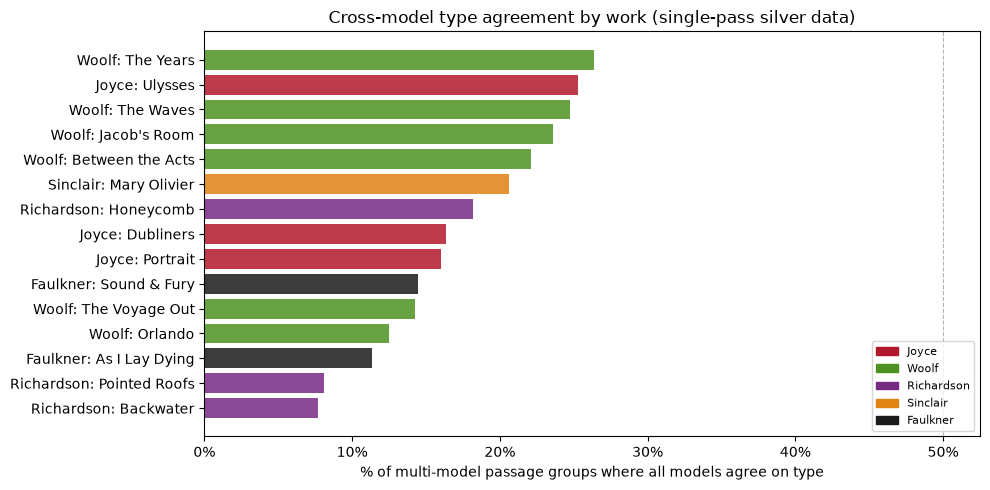

Saved: logs/q2_agreement.png

Works with agreement < 50% are strongest candidates for the ambiguity dataset (AMBIGUITY.md).


: 

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
works_sorted = agree_df.index.tolist()
agree_pcts = agree_df["agree_pct"].values
colors = [AUTHOR_COLORS.get(w.split(":")[0], "grey") for w in works_sorted]

ax.barh(works_sorted, agree_pcts, color=colors, alpha=0.85)
ax.axvline(50, color="grey", linestyle="--", linewidth=0.8, alpha=0.6)
ax.set_xlabel("% of multi-model passage groups where all models agree on type")
ax.set_title("Cross-model type agreement by work (single-pass silver data)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())

legend_elements = [plt.Rectangle((0,0),1,1, color=c, label=a) for a, c in AUTHOR_COLORS.items()]
ax.legend(handles=legend_elements, loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig("logs/q2_agreement.png", dpi=150)
plt.show()
print("Saved: logs/q2_agreement.png")
print()
print("Works with agreement < 50% are strongest candidates for the ambiguity dataset (AMBIGUITY.md).")